# Build an additive baseline

**Goal:** Encode variants, respect official splits, fit ridge regression on training data only.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("../data/raw/four_mutations_full_data.csv.zip")

df = pd.read_csv(data_path)

df_model = df[df["keep"] == True].copy()

train_df = df_model[df_model["sampled"] == "train"].copy()
test_df = df_model[df_model["sampled"] == "test"].copy()

print("Training:", len(train_df))
print("Testing:", len(test_df))

Training: 6988
Testing: 1745


C:\Users\mw645\AppData\Local\Temp\ipykernel_25812\2680092277.py:7: DtypeWarning: Columns (8: one_vs_rest_validation, 10: two_vs_rest_validation, 12: three_vs_rest_validation) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


One-hot encoding - convert AA sequence into numbers
4 positions x 20 AA = 80 numbers

In [2]:
amino_acids = "ACDEFGHIKLMNPQRSTVWY"

def one_hot_encode(variant):
    encoding = np.zeros((4, 20))

    for position, amino_acid in enumerate(variant):
        aa_index = amino_acids.index(amino_acid)
        encoding[position, aa_index] = 1

    return encoding.flatten()

example = one_hot_encode("VDGV")

print("Shape:", example.shape)
print("Number of ones:", example.sum())

Shape: (80,)
Number of ones: 4.0


In [3]:
X_train = np.stack(train_df["Variants"].apply(one_hot_encode))
X_test = np.stack(test_df["Variants"].apply(one_hot_encode))

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (6988, 80)
Test shape: (1745, 80)


In [ ]:
#create target values
y_train = train_df["Fitness"].to_numpy()
y_test = test_df["Fitness"].to_numpy()

print("Training targets:", y_train.shape)
print("Test targets:", y_test.shape)
print("First five fitness values:", y_train[:5])

Training targets: (6988,)
Test targets: (1745,)
First five fitness values: [1.         1.44590509 1.17054988 2.4012435  1.83818718]


Start with Ridge Regression (not a neural network). RR learns a contribution for each amino acid at each position.

In [5]:
from sklearn.linear_model import Ridge

baseline = Ridge(alpha=1.0)
baseline.fit(X_train, y_train)

print("Model trained!")

Model trained!


In [6]:
#evaluate
from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr

y_pred = baseline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
spearman = spearmanr(y_test, y_pred).statistic

print("RMSE:", round(rmse, 3))
print("Spearman correlation:", round(spearman, 3))

RMSE: 0.855
Spearman correlation: 0.788


RMSE (root mean squared error): How far are our predicted fitness values from the experimentally measured values? Lower is better. An RMSE of 0 would mean perfect predictions.
Spearman correlation: Does the model correctly rank variants from lower to higher fitness? It ranges from −1 to +1, with +1 being perfect ranking.

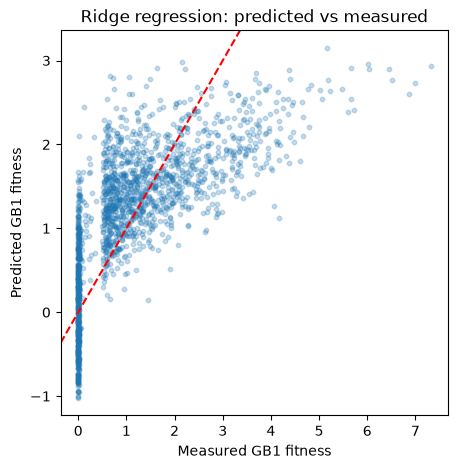

In [7]:
#visualise
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))

plt.scatter(y_test, y_pred, alpha=0.25, s=10)

plt.xlabel("Measured GB1 fitness")
plt.ylabel("Predicted GB1 fitness")
plt.title("Ridge regression: predicted vs measured")

plt.axline((0, 0), slope=1, color="red", linestyle="--")

plt.show()